In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('employee_attrition_dataset.csv')
df

,Employee_ID,Age,Department,Job_Role,Salary,Years_At_Company,Number_of_Promotions,Performance_Rating,Job_Satisfaction,Work_Life_Balance,Overtime,Distance_From_Workplace_KM,Training_Opportunities,Manager_Rating,Monthly_Working_Hours,Attrition
0,EMP100000,25,Engineering,Engineering Manager,51360,2,0,3,3,3,Yes,28,4,2,202,No
1,EMP100001,26,IT,IT Manager,34039,0,0,3,2,3,No,36,5,3,161,Yes
2,EMP100002,46,Operations,Operations Manager,68143,2,3,3,3,2,Yes,23,3,4,159,Yes
3,EMP100003,43,Marketing,Product Marketing Manager,61258,4,0,3,4,2,No,3,3,4,217,Yes
4,EMP100004,49,Sales,Sales Manager,46385,0,0,4,4,3,No,24,4,4,153,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,EMP104995,31,IT,IT Support Specialist,81549,8,1,2,4,3,No,34,1,4,172,No
4996,EMP104996,33,Sales,Sales Executive,53100,5,0,4,1,4,No,24,6,3,175,No
4997,EMP104997,39,Engineering,Engineering Manager,48647,1,1,3,3,3,No,21,4,3,160,No
4998,EMP104998,42,Operations,Operations Manager,65340,4,0,4,1,3,Yes,13,2,4,250,No


In [3]:
df.shape

(5000, 16)

In [4]:
df.head()

,Employee_ID,Age,Department,Job_Role,Salary,Years_At_Company,Number_of_Promotions,Performance_Rating,Job_Satisfaction,Work_Life_Balance,Overtime,Distance_From_Workplace_KM,Training_Opportunities,Manager_Rating,Monthly_Working_Hours,Attrition
0,EMP100000,25,Engineering,Engineering Manager,51360,2,0,3,3,3,Yes,28,4,2,202,No
1,EMP100001,26,IT,IT Manager,34039,0,0,3,2,3,No,36,5,3,161,Yes
2,EMP100002,46,Operations,Operations Manager,68143,2,3,3,3,2,Yes,23,3,4,159,Yes
3,EMP100003,43,Marketing,Product Marketing Manager,61258,4,0,3,4,2,No,3,3,4,217,Yes
4,EMP100004,49,Sales,Sales Manager,46385,0,0,4,4,3,No,24,4,4,153,No


In [5]:
missing_count = df.isnull().sum()
print('Missing Values per column:')
print(missing_count[missing_count > 0] if missing_count.sum() > 0 else "No missing values detected")


Missing Values per column:
No missing values detected


In [6]:
dup_count = df.duplicated().sum()
dup_count

np.int64(0)

In [7]:
df["Department"].unique()

<StringArray>
['Engineering', 'IT', 'Operations', 'Marketing', 'Sales', 'HR', 'Finance']
Length: 7, dtype: str

In [8]:
df["Overtime"].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [9]:
df["Overtime"].value_counts()

Overtime
No     3650
Yes    1350
Name: count, dtype: int64

In [10]:
df["Attrition"].value_counts()

Attrition
No     3393
Yes    1607
Name: count, dtype: int64

Attrition_counts:


,Employees
Attrition,
No,3393
Yes,1607


Historical attrition rate: 32.1%


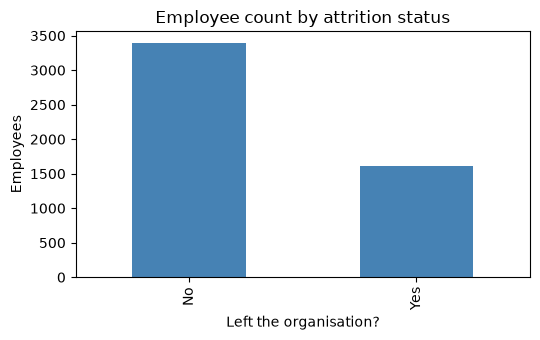

In [11]:
eda = df.copy()
eda["Attrition_Flag"] = eda["Attrition"].map({"No": 0, "Yes": 1})
attrition_counts = eda["Attrition"].value_counts().reindex(["No", "Yes"])

print("Attrition_counts:")
display(attrition_counts.to_frame('Employees'))
print(f"Historical attrition rate: {eda['Attrition_Flag'].mean():.1%}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
attrition_counts.plot.bar(ax=ax, color="steelblue")
ax.set(title="Employee count by attrition status",xlabel='Left the organisation?', ylabel= "Employees")
plt.tight_layout()
plt.show()



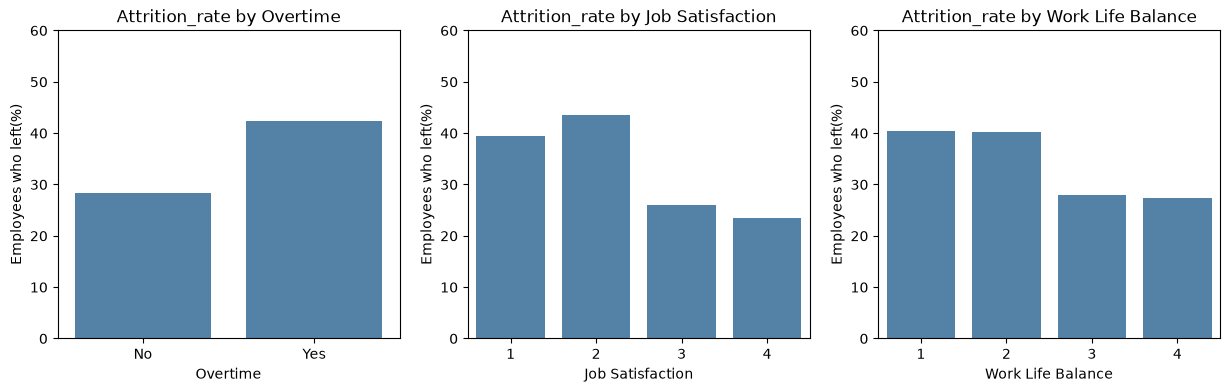

In [12]:
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax, col in zip(axes,['Overtime', 'Job_Satisfaction', 'Work_Life_Balance' ]):
    rates = (eda.groupby(col)['Attrition_Flag'].mean() * 100).sort_index()
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color='steelblue')
    ax.set(title=f"Attrition_rate by {col.replace('_', ' ')}", xlabel=col.replace('_', ' '), ylabel="Employees who left(%)",ylim=(0,60))

plt.tight_layout
plt.show()

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Employee_ID                 5000 non-null   str  
 1   Age                         5000 non-null   int64
 2   Department                  5000 non-null   str  
 3   Job_Role                    5000 non-null   str  
 4   Salary                      5000 non-null   int64
 5   Years_At_Company            5000 non-null   int64
 6   Number_of_Promotions        5000 non-null   int64
 7   Performance_Rating          5000 non-null   int64
 8   Job_Satisfaction            5000 non-null   int64
 9   Work_Life_Balance           5000 non-null   int64
 10  Overtime                    5000 non-null   str  
 11  Distance_From_Workplace_KM  5000 non-null   int64
 12  Training_Opportunities      5000 non-null   int64
 13  Manager_Rating              5000 non-null   int64
 14  Monthly_Working_Hou

In [14]:
model_df = df.copy()
model_df['Has_promotions'] = (model_df['Number_of_Promotions'] > 0).astype(int)

y = model_df['Attrition'].map({'No':0, 'Yes':1})
x = model_df.drop(columns= ['Attrition','Employee_ID'])

categorical_cols = x.select_dtypes(include= ['object', 'category']).columns.tolist()
numeric_cols = x.select_dtypes(include= np.number).columns.tolist()


/var/folders/zc/n7wqbvhj7n15lbz3_kt5w8180000gn/T/ipykernel_10541/2269784138.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x.select_dtypes(include= ['object', 'category']).columns.tolist()


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay



In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    x,y, test_size=0.20, random_state=42,stratify=y
    )

In [17]:
len(X_train),len(y_train)

(4000, 4000)

In [19]:
%pip install imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn]
Note: you may need to restart the kernel to use updated packages.


In [20]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imPipeline


In [21]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy= 'median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy= 'most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_cols),
    ('categorical', categorical_transformer, categorical_cols)
])

In [22]:
models = { 
    'LogisticRegression': imPipeline(steps=[
        ('preprocess', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'RandomForest': imPipeline(steps=[
        ('preprocess', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(random_state=42))
    ]),
}

In [23]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'Fitted {name}')

Fitted LogisticRegression
Fitted RandomForest


In [24]:
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    prod = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model Name': name,
        "Accuracy": accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index('Model Name')
display(results_df)

,Accuracy,Precision,Recall,F1
Model Name,,,,
LogisticRegression,0.609,0.423581,0.604361,0.498074
RandomForest,0.681,0.505682,0.277259,0.358149


In [25]:
lr_pipeline = models['LogisticRegression']
lr_model = lr_pipeline.named_steps['classifier']

In [26]:
preprocessor_fitted = lr_pipeline.named_steps['preprocess']
feature_names = preprocessor_fitted.get_feature_names_out()


In [27]:
coef = lr_model.coef_[0]

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef,
    'Importance': abs(coef),
})

In [28]:
feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

In [29]:
feature_importance.shape

(40, 3)

In [30]:
feature_importance.head(10)

,Feature,Coefficient,Importance
5,numeric__Job_Satisfaction,-0.359376,0.359376
39,categorical__Overtime_Yes,0.345647,0.345647
38,categorical__Overtime_No,-0.286225,0.286225
28,categorical__Job_Role_IT Support Specialist,-0.258104,0.258104
6,numeric__Work_Life_Balance,-0.244727,0.244727
11,numeric__Has_promotions,-0.231356,0.231356
27,categorical__Job_Role_IT Manager,0.223381,0.223381
23,categorical__Job_Role_Finance Manager,-0.222853,0.222853
33,categorical__Job_Role_Recruiter,-0.219638,0.219638
24,categorical__Job_Role_Financial Analyst,0.192919,0.192919


## Executive Summary

This problem presented an historical dataset of 5000 employees, where 1607 are labelled as left 